# EDA 1: First look at the historical match table

**Milestone 3, step 3.** Before any modelling we get to know the data: how much there is,
what it covers, what is missing, and what looks wrong.

- **Data:** openfootball/champions-league (CC0-1.0), seasons 2011-12 to 2025-26,
  parsed by `src/data/clean.py::load_openfootball()`.
- **Rule:** this notebook only *explores*. Reusable logic lives in `src/`; nothing here
  edits `data/raw/`.
- **Run:** in VS Code select the `.venv` kernel and *Run All*, or from the project root:
  `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda_first_look.ipynb`

**Vocabulary**
- **Observation:** one row = one match.
- **Feature:** an input known *before kickoff* (built in Milestone 5, not here).
- **Target:** what we predict, `result` (H / D / A), defined in Milestone 4.

In [1]:
# Setup: make the project root importable (the notebook runs from notebooks/).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import difflib
import re

import matplotlib.pyplot as plt
import pandas as pd

from src.data.clean import load_openfootball

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("project root:", ROOT)

project root: C:\Users\evans\dev\champions-league-prediction-model


## 1. Size and shape

In [2]:
df = load_openfootball()
print("rows (matches):", len(df), "| columns:", df.shape[1])
print("date range:", df["date"].min().date(), "to", df["date"].max().date())
df.dtypes

rows (matches): 1997 | columns: 18
date range: 2011-09-13 to 2026-05-30


season                     str
date             datetime64[s]
kickoff_local              str
stage                      str
stage_raw                  str
home_team                  str
home_country               str
away_team                  str
away_country               str
home_ft                  Int64
away_ft                  Int64
home_ht                  Int64
away_ht                  Int64
home_aet                 Int64
away_aet                 Int64
home_pens                Int64
away_pens                Int64
source_file                str
dtype: object

In [3]:
df.head()

,season,date,kickoff_local,stage,stage_raw,home_team,home_country,away_team,away_country,home_ft,away_ft,home_ht,away_ht,home_aet,away_aet,home_pens,away_pens,source_file
0,2011-12,2011-09-13,20:45,group,Group E,Chelsea FC,ENG,Bayer Leverkusen,GER,2,0,0,0,<NA>,<NA>,<NA>,<NA>,2011-12_cl.txt
1,2011-12,2011-09-13,20:45,group,Group E,KRC Genk,BEL,Valencia CF,ESP,0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2011-12_cl.txt
2,2011-12,2011-09-13,20:45,group,Group F,Borussia Dortmund,GER,Arsenal FC,ENG,1,1,0,1,<NA>,<NA>,<NA>,<NA>,2011-12_cl.txt
3,2011-12,2011-09-13,20:45,group,Group F,Olympiakos Piraeus,GRE,Olympique Marseille,FRA,0,1,0,0,<NA>,<NA>,<NA>,<NA>,2011-12_cl.txt
4,2011-12,2011-09-13,20:45,group,Group G,APOEL Nikosia,CYP,Zenit St. Petersburg,RUS,2,1,0,0,<NA>,<NA>,<NA>,<NA>,2011-12_cl.txt


**What this shows:** 1,997 matches (observations) and 18 columns, from Sep 2011 to May 2026.
Score columns are `Int64` (nullable integers), so a missing score shows as `<NA>` rather
than being turned into 0 or a float. `date` is a real datetime, which we need for
chronological sorting and splitting.

## 2. Coverage: seasons and stages

In [4]:
stage_order = ["group", "league", "playoff", "round_of_16", "quarterfinal", "semifinal", "final"]
coverage = pd.crosstab(df["season"], df["stage"]).reindex(columns=stage_order, fill_value=0)
coverage["total"] = coverage.sum(axis=1)
coverage

stage,group,league,playoff,round_of_16,quarterfinal,semifinal,final,total
season,,,,,,,,
2011-12,96,0,0,16,8,4,1,125
2012-13,96,0,0,16,8,4,1,125
2013-14,96,0,0,16,8,4,1,125
2014-15,96,0,0,16,8,4,1,125
2015-16,96,0,0,16,8,4,1,125
2016-17,96,0,0,16,8,4,1,125
2017-18,96,0,0,16,8,4,1,125
2018-19,96,0,0,16,8,4,1,125
2019-20,96,0,0,16,4,2,1,119


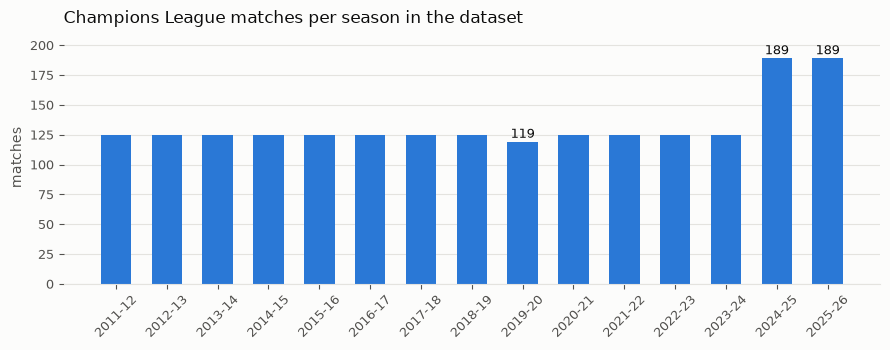

In [5]:
# Matches per season (single series: one colour, no legend; the title names it).
SURFACE, INK, INK_2, GRID, BLUE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
per_season = coverage["total"]

fig, ax = plt.subplots(figsize=(9, 3.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.bar(per_season.index, per_season.values, width=0.6, color=BLUE, zorder=2)
ax.set_title("Champions League matches per season in the dataset", loc="left", color=INK, fontsize=12)
ax.set_ylabel("matches", color=INK_2)
ax.set_ylim(0, per_season.max() * 1.12)  # headroom for the labels
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=INK_2, labelsize=9)
ax.tick_params(axis="x", rotation=45)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
# Selective direct labels: only the seasons that differ from the usual 125.
for i, (season, n) in enumerate(per_season.items()):
    if n != 125:
        ax.annotate(str(n), (i, n), xytext=(0, 3), textcoords="offset points",
                    ha="center", color=INK, fontsize=9)
fig.tight_layout()
plt.show()

**What this shows:** three competition formats.

| Seasons | Format | Matches |
|---|---|---|
| 2011-12 to 2023-24 (except 2019-20) | 32 teams, 8 groups of 4 (96 group matches) + two-legged knockouts + final | 125 |
| 2019-20 | Same group stage; COVID-19 moved the quarter-finals onwards to single matches | 119 |
| 2024-25, 2025-26 | 36-team league phase (144), knockout play-offs (16), then knockouts | 189 |

**Why it matters for modelling:**
- The two newest seasons are the most similar to the season we will predict (2026-27),
  and they make up about 19% of the data. A chronological split will put them in
  validation/test, so we evaluate on the current format.
- In the old format a team played 6 group matches; now it plays 8 league matches
  against 8 different opponents. Form features (last 5 matches) are computed the same
  way in both formats, but the opponents behind them differ.

## 3. Missing values

In [6]:
missing = pd.DataFrame({"missing": df.isna().sum(), "share": df.isna().mean().round(3)})
missing[missing["missing"] > 0]

,missing,share
home_ht,112,0.056
away_ht,112,0.056
home_aet,1973,0.988
away_aet,1973,0.988
home_pens,1985,0.994
away_pens,1985,0.994


In [7]:
# Why is the half-time score missing? Compare those matches' 90-minute scores.
no_ht = df[df["home_ht"].isna()]
print("matches without half-time score:", len(no_ht))
print("their 90-minute scores:")
print((no_ht["home_ft"].astype(str) + "-" + no_ht["away_ft"].astype(str)).value_counts().to_string())
print("\nmatches that finished 0-0 after 90 min, in total:",
      int(((df["home_ft"] == 0) & (df["away_ft"] == 0)).sum()))

matches without half-time score: 112
their 90-minute scores:
0-0    112

matches that finished 0-0 after 90 min, in total: 112


In [8]:
# Extra time and penalties should only happen in knockout rounds.
went_long = df[df["home_aet"].notna()]
print("extra-time matches by stage:", went_long["stage"].value_counts().to_dict())
print("penalty shootouts by stage:", df[df["home_pens"].notna()]["stage"].value_counts().to_dict())

extra-time matches by stage: {'round_of_16': 14, 'final': 4, 'quarterfinal': 3, 'semifinal': 2, 'playoff': 1}
penalty shootouts by stage: {'round_of_16': 7, 'final': 3, 'semifinal': 1, 'quarterfinal': 1}


**What this shows:**
- **Extra time / penalties are missing for ~99% of matches. That is expected, not a
  problem:** they only exist when a knockout tie is level, and both appear only in
  knockout stages (no group or league matches).
- **Half-time scores are missing for 112 matches, and every one of them finished 0-0.**
  There are exactly 112 goalless matches in total, so the source omits the half-time
  score when it can only be 0-0. This missingness is *informative* (not random).
  Decision for cleaning (step 4): fill these with 0-0 **and** add a flag column
  `ht_inferred`, so the inference stays visible.

## 4. Duplicates

In [9]:
print("exact duplicate rows:", int(df.duplicated().sum()))
key = ["date", "home_team", "away_team"]
print("duplicate (date, home, away):", int(df.duplicated(subset=key).sum()))
# A team should play at most once per day.
long = pd.concat([df[["date", "home_team"]].rename(columns={"home_team": "team"}),
                  df[["date", "away_team"]].rename(columns={"away_team": "team"})])
print("team playing twice on the same date:", int(long.duplicated().sum()))
# Same home/away pairing twice within a season (normal two-legged ties swap home/away).
same_fixture = df.duplicated(subset=["season", "home_team", "away_team"], keep=False)
print("same home-v-away pairing twice in one season:", int(same_fixture.sum()), "rows")
df[same_fixture].sort_values(["season", "home_team", "date"])[
    ["season", "date", "stage", "home_team", "away_team", "home_ft", "away_ft"]].head(12)

exact duplicate rows: 0
duplicate (date, home, away): 0
team playing twice on the same date: 0
same home-v-away pairing twice in one season: 42 rows


,season,date,stage,home_team,away_team,home_ft,away_ft
79,2011-12,2011-11-23,group,AC Milan,FC Barcelona,2,3
115,2011-12,2012-03-28,quarterfinal,AC Milan,FC Barcelona,0,0
6,2011-12,2011-09-13,group,FC Barcelona,AC Milan,2,2
117,2011-12,2012-04-03,quarterfinal,FC Barcelona,AC Milan,3,1
172,2012-13,2012-10-24,group,Borussia Dortmund,Real Madrid,2,1
246,2012-13,2013-04-24,semifinal,Borussia Dortmund,Real Madrid,4,1
180,2012-13,2012-11-06,group,Real Madrid,Borussia Dortmund,2,2
247,2012-13,2013-04-30,semifinal,Real Madrid,Borussia Dortmund,2,0
466,2014-15,2014-12-10,group,FC Barcelona,Paris Saint-Germain,3,1
491,2014-15,2015-04-21,quarterfinal,FC Barcelona,Paris Saint-Germain,2,0


**What this shows:** no duplicated matches and no team playing twice on one day.
The 42 rows with the same home-v-away pairing twice in a season are **genuine**: the two
clubs met in the group stage and again in a knockout round (e.g. AC Milan v Barcelona
in the 2011-12 group stage and quarter-final). Nothing needs removing.

## 5. Team names: first look for spelling variants

In [10]:
teams = pd.concat([df[["home_team", "home_country", "season"]].set_axis(["team", "country", "season"], axis=1),
                   df[["away_team", "away_country", "season"]].set_axis(["team", "country", "season"], axis=1)])
summary = teams.groupby(["team", "country"]).agg(seasons=("season", "nunique"),
                                                  first=("season", "min"), last=("season", "max"))
print("distinct team names:", teams["team"].nunique(),
      "| distinct (name, country) pairs:", len(summary))
names_in_two_countries = teams.groupby("team")["country"].nunique()
print("names listed under more than one country:", names_in_two_countries[names_in_two_countries > 1].to_dict())

distinct team names: 136 | distinct (name, country) pairs: 136
names listed under more than one country: {}


In [11]:
# Candidate variants: names in the same country that become identical after removing
# common club prefixes/suffixes, or that are very similar strings.
CLUB_WORDS = r"\b(fc|cf|afc|ac|as|ssc|sc|sk|fk|bk|kv|krc|rsc|psv|sv|vfl|vfb|tsg|rb|1\.|club|de|calcio)\b"

def name_key(name: str) -> str:
    key = re.sub(CLUB_WORDS, " ", name.lower())
    return re.sub(r"[^a-z0-9à-ÿ]+", " ", key).strip()

summary = summary.reset_index()
summary["key"] = summary["team"].map(name_key)
same_key = summary[summary.duplicated(subset=["country", "key"], keep=False)]
print("groups with the same simplified name:", same_key.groupby(["country", "key"]).ngroups)
same_key.sort_values(["country", "key", "first"])[["country", "team", "first", "last", "seasons"]]

groups with the same simplified name:

 13


,country,team,first,last,seasons
116,CZE,Slavia Praha,2019-20,2019-20,1
109,CZE,SK Slavia Praha,2025-26,2025-26,1
76,ENG,Manchester City,2011-12,2022-23,12
77,ENG,Manchester City FC,2023-24,2025-26,3
78,ENG,Manchester United,2011-12,2021-22,8
79,ENG,Manchester United FC,2023-24,2023-24,1
125,ENG,Tottenham Hotspur,2016-17,2022-23,5
126,ENG,Tottenham Hotspur FC,2025-26,2025-26,1
15,ESP,Atlético Madrid,2013-14,2022-23,10
30,ESP,Club Atlético de Madrid,2023-24,2025-26,3


In [12]:
# Near-identical strings that the simple key above did not group (possible variants to review).
pairs = []
for country, group in summary.groupby("country"):
    names = group["team"].tolist()
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            ratio = difflib.SequenceMatcher(None, name_key(a), name_key(b)).ratio()
            if ratio >= 0.6 and name_key(a) != name_key(b):
                pairs.append((country, a, b, round(ratio, 2)))
pd.DataFrame(pairs, columns=["country", "name_a", "name_b", "similarity"]).sort_values("similarity", ascending=False)

,country,name_a,name_b,similarity
20,GER,Bayer 04 Leverkusen,Bayer Leverkusen,0.91
2,CRO,Dinamo Zagreb,GNK Dinamo Zagreb,0.87
23,ITA,Atalanta,Atalanta BC,0.84
31,POR,Sporting Clube de Braga,Sporting Clube de Portugal,0.84
27,POR,Sporting Braga,Sporting Clube de Braga,0.82
11,ENG,Manchester City FC,Manchester United FC,0.81
8,ENG,Manchester City,Manchester United,0.81
10,ENG,Manchester City FC,Manchester United,0.81
9,ENG,Manchester City,Manchester United FC,0.81
18,ESP,Real Sociedad,Real Sociedad de Fútbol,0.79


**What this shows:** the 136 "teams" are fewer real clubs.

- **A naming change in the source around 2023-24.** Short names became official ones:
  `Real Madrid` → `Real Madrid CF`, `Bayern München` → `FC Bayern München`,
  `Atlético Madrid` → `Club Atlético de Madrid`. The biggest clubs are split across
  two names exactly at the seasons closest to today, which is the worst place for form
  features to restart.
- **String similarity cannot decide alone.** Real variants score anywhere from 0.62
  (`SL Benfica` / `Sport Lisboa e Benfica`) to 0.91 (`Bayer 04 Leverkusen` /
  `Bayer Leverkusen`), while *different* clubs score just as high: Manchester City v
  Manchester United (0.81), Sporting Braga v Sporting CP (0.72), Sparta v Slavia Praha (0.75).
  Any automatic threshold would either miss variants or merge rivals.
- **Decision for cleaning (step 4):** a hand-reviewed mapping table (variant → canonical
  name), with similarity used only to *suggest* candidates, plus a validation check
  that fails if any team name is not in the table. The same table will map
  football-data.org names for the 2026-27 fixtures.

## Summary of step 3

| Check | Result | Action |
|---|---|---|
| Size | 1,997 matches, 15 seasons, 2011-09-13 to 2026-05-30 | none |
| Coverage | 3 formats; the 2 newest seasons use the current 36-team format | keep in mind for the split (Milestone 6) |
| Duplicates | none; repeated pairings are genuine group + knockout meetings | none |
| Missing half-time | 112 matches, all 0-0 at 90 minutes | fill 0-0 with an `ht_inferred` flag (step 4) |
| Missing extra time / penalties | only knockout ties that were level | expected; keep as `<NA>` |
| Team names | systematic renaming around 2023-24 plus scattered variants | reviewed mapping table + validation (step 4) |

Still to check (steps 4-5): scores against a second source, neutral venues (finals,
2019-20 Lisbon), the kickoff timezone, goal distributions, the H/D/A split and home advantage.